# Rebuilding Netflix's billboard bandit: exploit vs incrementality, and how to evaluate it offline

Netflix's billboard (the big banner on the homepage) shows one title per member. In their [AI Council talk](https://aicouncil.com/talks/a-multi-armed-bandit-framework-for-recommendations-at-netflix), Jaya Kawale and team describe a contextual bandit for it:

- **Epsilon-greedy**: explore a random title from a candidate pool with probability ε, otherwise show the best-scoring one. The random slice doubles as unbiased training data.
- **Two exploit policies**: a *greedy* one (pick the title with the highest probability of play) and an *incrementality* one (pick the title whose play probability goes up the most because it was shown).
- **Replay** for offline evaluation: on uniform-exploration logs, keep the rows where the policy's pick matches the logged title, and average the reward.
- **Lessons**: greedy favors popular titles; titles with low baseline play probability often get the biggest lift; online, incrementality shifted plays to lesser-known titles. Future work: Thompson sampling, UCB.

This notebook rebuilds all of it on MovieLens, then pushes on two places the talk leaves open:
1. **Online algorithms** the talk names as future work — ε-greedy vs LinUCB vs Thompson sampling, with error bars over 5 seeds.
2. **Off-policy evaluation when the logs are not uniform.** Replay needs uniform logs. Real logs come from an ε-greedy system. We compare replay, IPS, SNIPS, the direct method and doubly robust against the known truth.

**Real:** ~890k MovieLens ratings → member and title taste vectors (matrix factorization), title popularity.
**Simulated:** plays. No public dataset logs billboard impressions. Plays come from stated, numbered assumptions. Because we wrote the simulator, we know the true value of every policy — that's what lets us grade the offline estimators.

Credit: the framework belongs to the Netflix authors. This is an independent educational rebuild.

In [1]:
# all imports in one cell
import os, urllib.request, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import svds
from sklearn.linear_model import LogisticRegression

SEED = 42
N_SEEDS = 5                    # every headline number is a mean over 5 seeds, with a spread
os.makedirs("figures", exist_ok=True)

## 1. Data → taste vectors

Plain operation: a truncated SVD of the "liked" matrix (rating ≥ 4 = 1). Each member and each title gets a 16-number vector; the cosine between them is the member's **affinity** for the title. We keep the 300 most-rated titles and members with ≥ 10 ratings among them.

In [2]:
PARQUET_URL = ("https://huggingface.co/datasets/ashraq/movielens_ratings/"
               "resolve/main/data/train-00000-of-00001-8c8c7645a52d95e5.parquet")
if not os.path.exists("ratings.parquet"):
    urllib.request.urlretrieve(PARQUET_URL, "ratings.parquet")

df = pd.read_parquet("ratings.parquet").rename(columns={"movie_id": "movieId", "user_id": "userId"})
top = df.groupby("movieId").size().sort_values(ascending=False).index[:300]
d = df[df.movieId.isin(top)]
uc = d.groupby("userId").size()
d = d[d.userId.isin(uc[uc >= 10].index)]

uidx = {u: i for i, u in enumerate(d.userId.unique())}
tidx = {t: i for i, t in enumerate(top)}
liked = (d.rating >= 4).astype(float).values
M = csr_matrix((liked, (d.userId.map(uidx).values, d.movieId.map(tidx).values)),
               shape=(len(uidx), len(tidx)))

u_, s_, vt_ = svds(M, k=16)                      # truncated SVD
U = u_ * np.sqrt(s_); V = vt_.T * np.sqrt(s_)
U -= U.mean(0); V -= V.mean(0)                   # center (lesson from the MAPS rebuild)
Un = U / (np.linalg.norm(U, axis=1, keepdims=True) + 1e-9)
Vn = V / (np.linalg.norm(V, axis=1, keepdims=True) + 1e-9)

counts = d.groupby("movieId").size().reindex(top).values
pop = (np.log(counts) - np.log(counts).mean()) / np.log(counts).std()   # standardized log-popularity
titles = df.drop_duplicates("movieId").set_index("movieId").title.reindex(top).values
print(f"{len(uidx)} members, {len(top)} titles, {len(d)} ratings")

16720 members, 300 titles, 500846 ratings


## 2. The billboard world (simulated, every assumption numbered)

- **Candidate pool:** 20 titles, every 15th title by popularity rank (rank 1, 16, 31, …). A spread from blockbusters to niche, like a real billboard pool.
- **Assumption 1 — organic plays.** If a title is *not* on the billboard, a member still plays it with probability `p0 = sigmoid(−4.0 + 2.5·affinity + 0.8·popularity)`. Popular titles get played anyway.
- **Assumption 2 — billboard bonus.** On the billboard, the log-odds get a bonus `b = 1.6 − 0.5·popularity`: `p1 = sigmoid(logit(p0) + b)`. Being shown helps lesser-known titles more (awareness). This encodes the pattern in Netflix's scatterplot; it is an assumption here, not a finding.
- **Assumption 3 — reward.** Billboard reward = the member plays the billboard title (Netflix's "take rate"). For the other pool titles we also log organic plays — that's the data the incrementality model needs.
- **Assumption 4 — what we care about.** Incremental plays = `p1 − p0` of the shown title: plays that only happened *because* of the billboard.

Constants were picked so the average take rate is ~11% and the organic rate ~3%.

In [3]:
POOL = np.arange(0, 300, 15)                 # 20 titles across the popularity range
K = len(POOL)
A_all = Un @ Vn[POOL].T                       # (members, 20) affinity matrix
Z0 = -4.0 + 2.5 * A_all + 0.8 * pop[POOL]      # Assumption 1
P0 = 1 / (1 + np.exp(-Z0))
BONUS = 1.6 - 0.5 * pop[POOL]                  # Assumption 2
P1 = 1 / (1 + np.exp(-(Z0 + BONUS)))
LIFT = P1 - P0                                 # Assumption 4
N_USERS = len(Un)

print(f"mean organic p0 {P0.mean():.3f} | mean billboard p1 {P1.mean():.3f} | mean lift {LIFT.mean():.3f}")
pd.DataFrame({"title": titles[POOL], "popularity": pop[POOL].round(2),
              "avg p0": P0.mean(0).round(3), "avg p1": P1.mean(0).round(3),
              "avg lift": LIFT.mean(0).round(3)}).head(6)

mean organic p0 0.034 | mean billboard p1 0.107 | mean lift 0.072


,title,popularity,avg p0,avg p1,avg lift
0,The Martian (2015),2.88,0.166,0.188,0.022
1,Frozen (2013),1.91,0.087,0.150,0.062
2,About Time (2013),1.38,0.058,0.129,0.071
3,Bridge of Spies (2015),1.23,0.052,0.125,0.073
4,Incredibles 2 (2018),0.81,0.039,0.114,0.075
5,It Follows (2014),0.56,0.033,0.109,0.076


**Logging.** One function simulates billboard visits under any logging policy. It returns, per visit: member, shown title, the **propensity** (probability the logging policy had of showing that title — logged at serving time, as Netflix does), the billboard play, and organic plays of the 19 other pool titles.

In [4]:
def features(users, arms):
    # member-title features: elementwise product of taste vectors + a one-hot of the title
    x = Un[users] * Vn[POOL[arms]]
    onehot = np.eye(K)[arms]
    return np.hstack([x, onehot])

def log_visits(rng, n, policy_probs):
    # policy_probs(users) -> (n, K) matrix of show-probabilities; rows sum to 1
    users = rng.integers(0, N_USERS, n)
    probs = policy_probs(users)
    cum = probs.cumsum(1)
    arms = (rng.random((n, 1)) < cum).argmax(1)          # sample the shown title
    prop = probs[np.arange(n), arms]
    play = (rng.random(n) < P1[users, arms]).astype(int)  # billboard play
    organic = (rng.random((n, K)) < P0[users]).astype(int)  # organic plays, all pool titles
    organic[np.arange(n), arms] = -1                      # shown title: not an organic observation
    return dict(users=users, arms=arms, prop=prop, play=play, organic=organic)

uniform = lambda users: np.full((len(users), K), 1.0 / K)

## 3. Netflix's experiment: greedy exploit vs incrementality

Plain operations:
1. Log 40,000 visits with **uniform** exploration.
2. Fit two logistic regressions on the same features: **p̂1** = P(play | shown) from billboard rows, **p̂0** = P(play | not shown) from organic rows.
3. **Greedy** shows `argmax p̂1`. **Incrementality** shows `argmax (p̂1 − p̂0)`.
4. Score both on 20,000 fresh members with the *true* probabilities, and also with Netflix's **replay** on a held-out uniform log.

Repeated for 5 seeds.

In [5]:
def fit_models(log, rng):
    # p1-hat: billboard rows
    X1 = features(log["users"], log["arms"])
    m1 = LogisticRegression(C=1.0, max_iter=2000).fit(X1, log["play"])
    # p0-hat: organic rows (subsample 200k for speed)
    uu, aa = np.nonzero(log["organic"] >= 0)
    sel = rng.choice(len(uu), size=min(200_000, len(uu)), replace=False)
    users0, arms0 = log["users"][uu[sel]], aa[sel]
    y0 = log["organic"][uu[sel], aa[sel]]
    m0 = LogisticRegression(C=1.0, max_iter=2000).fit(features(users0, arms0), y0)
    return m1, m0

def score_all(model, users):
    # predicted probability for every (member, pool title) pair -> (n, K)
    n = len(users)
    X = features(np.repeat(users, K), np.tile(np.arange(K), n))
    return model.predict_proba(X)[:, 1].reshape(n, K)

def replay(log, picks):
    # Netflix's replay: keep rows where the policy's pick == logged title, average the reward
    m = picks == log["arms"]
    return log["play"][m].mean(), m.sum()

TOP5 = np.argsort(-pop[POOL])[:5]
rows = []
for s in range(N_SEEDS):
    rng = np.random.default_rng(SEED + s)
    train = log_visits(rng, 40_000, uniform)
    m1, m0 = fit_models(train, rng)
    test_users = rng.integers(0, N_USERS, 20_000)
    p1h, p0h = score_all(m1, test_users), score_all(m0, test_users)
    holdout = log_visits(rng, 40_000, uniform)
    h1, h0 = score_all(m1, holdout["users"]), score_all(m0, holdout["users"])
    for name, picks, hp in [("greedy", p1h.argmax(1), h1.argmax(1)),
                            ("incrementality", (p1h - p0h).argmax(1), (h1 - h0).argmax(1)),
                            ("random", rng.integers(0, K, len(test_users)), rng.integers(0, K, len(holdout["users"]))),
                            ("oracle greedy", P1[test_users].argmax(1), P1[holdout["users"]].argmax(1)),
                            ("oracle incremental", LIFT[test_users].argmax(1), LIFT[holdout["users"]].argmax(1))]:
        rows.append(dict(seed=s, policy=name,
                         take_rate=P1[test_users, picks].mean(),
                         incremental=LIFT[test_users, picks].mean(),
                         top5_share=np.isin(picks, TOP5).mean(),
                         replay_take=replay(holdout, hp)[0]))
res = pd.DataFrame(rows)
summary = res.groupby("policy")[["take_rate", "incremental", "top5_share", "replay_take"]].agg(["mean", "std"]).round(4)
summary

take_rate         incremental         top5_share          \
                        mean     std        mean     std       mean     std   
policy                                                                        
greedy                0.2811  0.0010      0.1230  0.0023     0.6465  0.0151   
incrementality        0.2288  0.0047      0.1576  0.0013     0.2638  0.0320   
oracle greedy         0.2833  0.0006      0.1235  0.0004     0.6444  0.0019   
oracle incremental    0.2328  0.0006      0.1613  0.0003     0.2474  0.0034   
random                0.1065  0.0003      0.0722  0.0002     0.2497  0.0019   

                   replay_take          
                          mean     std  
policy                                  
greedy                  0.2865  0.0058  
incrementality          0.2330  0.0112  
oracle greedy           0.2886  0.0072  
oracle incremental      0.2357  0.0069  
random                  0.1002  0.0079

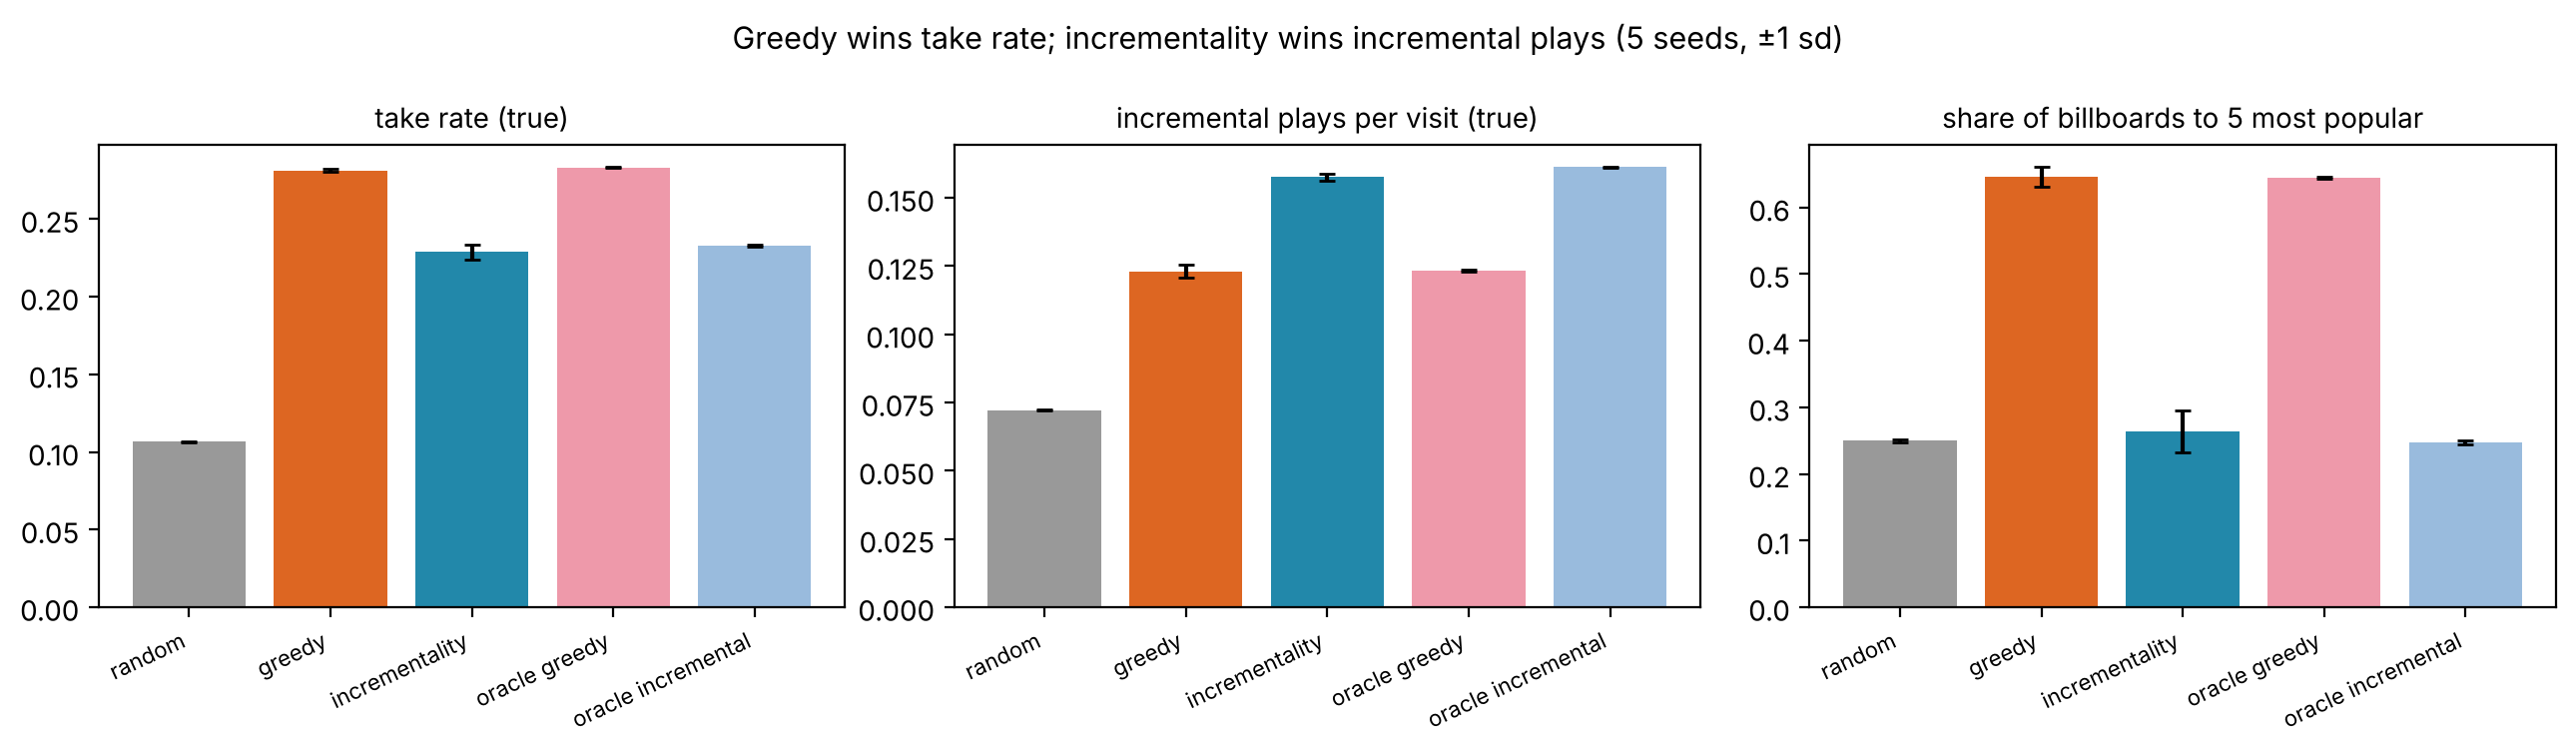

In [6]:
order = ["random", "greedy", "incrementality", "oracle greedy", "oracle incremental"]
g = res.groupby("policy")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col, lab in zip(axes, ["take_rate", "incremental", "top5_share"],
                        ["take rate (true)", "incremental plays per visit (true)", "share of billboards to 5 most popular"]):
    m = g[col].mean().reindex(order); sd = g[col].std().reindex(order)
    ax.bar(range(len(order)), m, yerr=sd, capsize=3,
           color=["#999", "#d62", "#28a", "#e9a", "#9bd"])
    ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=25, ha="right", fontsize=8)
    ax.set_title(lab, fontsize=10)
plt.suptitle("Greedy wins take rate; incrementality wins incremental plays (5 seeds, ±1 sd)", fontsize=11)
plt.tight_layout(); plt.savefig("figures/fig1_exploit_vs_incr.png", dpi=130); plt.show()

**How to read it.** Netflix's offline result was that greedy looked slightly better than incrementality. That's what replay on take rate says here too (`replay_take` column). But take rate counts plays that would have happened anyway. On *incremental* plays — the thing the billboard is for — incrementality wins, and it stops spending most billboards on blockbusters. The metric you evaluate on decides which policy "wins". That's the whole lesson of the talk in one chart.

Now Netflix's scatterplot: estimated baseline vs estimated lift per title, recovered from the logs (not from the simulator).

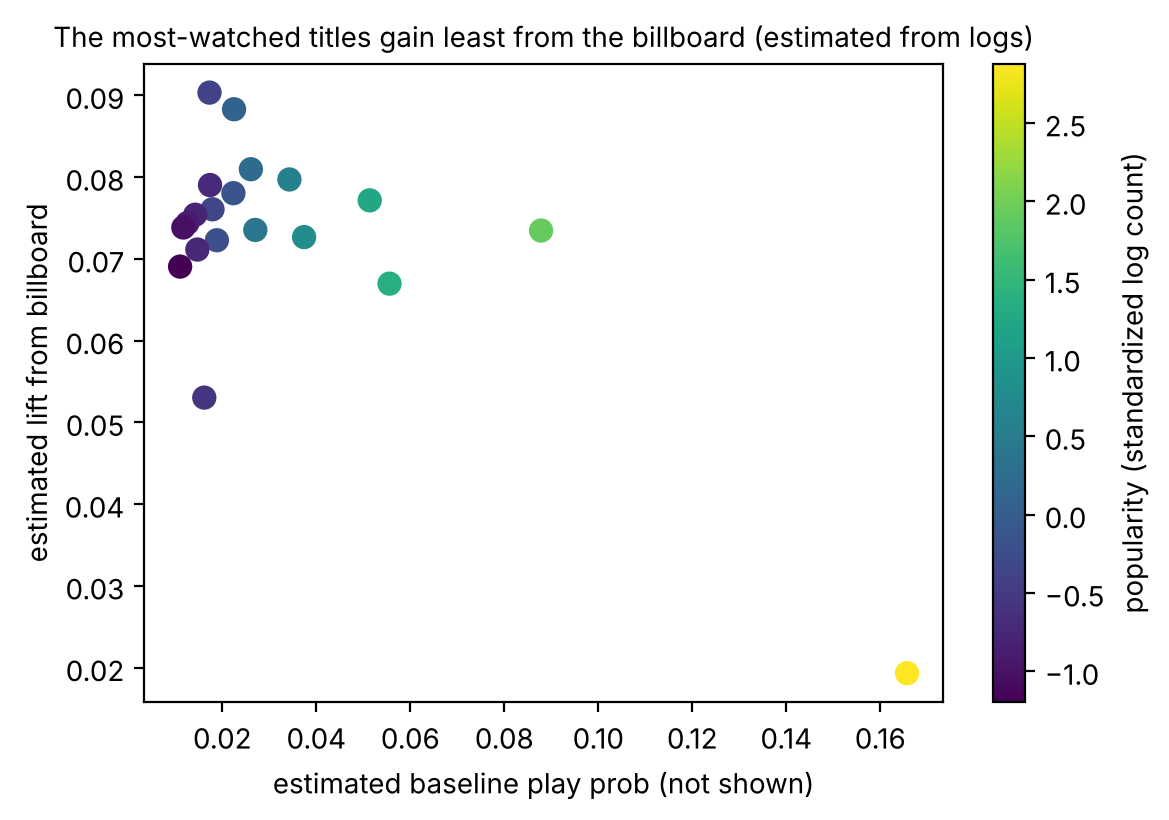

correlation(estimated lift, true avg lift): 0.865


In [7]:
rng = np.random.default_rng(SEED)
train = log_visits(rng, 40_000, uniform)
m1, m0 = fit_models(train, rng)
sample_users = rng.integers(0, N_USERS, 5000)
p1h, p0h = score_all(m1, sample_users), score_all(m0, sample_users)
base_hat, lift_hat = p0h.mean(0), (p1h - p0h).mean(0)

plt.figure(figsize=(6, 4.2))
sc = plt.scatter(base_hat, lift_hat, c=pop[POOL], cmap="viridis", s=60)
plt.colorbar(sc, label="popularity (standardized log count)")
plt.xlabel("estimated baseline play prob (not shown)")
plt.ylabel("estimated lift from billboard")
plt.title("The most-watched titles gain least from the billboard (estimated from logs)", fontsize=10)
plt.tight_layout(); plt.savefig("figures/fig2_baseline_vs_lift.png", dpi=130); plt.show()
print("correlation(estimated lift, true avg lift):",
      np.corrcoef(lift_hat, LIFT[sample_users].mean(0))[0, 1].round(3))

## 4. Beyond the talk: online bandits (ε-greedy vs LinUCB vs Thompson sampling)

The talk names Thompson sampling and UCB as future work. Here all three run **online**: each visit, the algorithm picks a title, sees the play, updates. Plain operation for all three: one ridge regression per title, on the member's taste vector (16 numbers + intercept). They differ only in how they explore:

- **ε-greedy (ε = 0.1):** 10% random title, else the best predicted.
- **LinUCB (α = 0.5):** best predicted + a bonus for titles the model is unsure about.
- **Linear Thompson sampling (v = 0.3):** draw plausible weights from each title's posterior, pick the best draw.

Reward = billboard play (take). **Regret** = plays lost vs the oracle that knows `p1`. 20,000 visits, 5 seeds.

**Fairness check first:** each algorithm has one knob (ε, α, v). A bad default can make any of them look bad, so we tune each knob on two *separate* seeds, then compare on the 5 main seeds.

In [8]:
D = Un.shape[1] + 1
def ctx(u): return np.append(Un[u], 1.0)

def run_bandit(algo, T, rng, eps=0.1, alpha=0.5, v=0.3, lam=1.0):
    A_inv = np.repeat(np.eye(D)[None] / lam, K, axis=0)   # per-title inverse Gram matrix
    b = np.zeros((K, D))
    regret = np.zeros(T)
    users = rng.integers(0, N_USERS, T)
    for t in range(T):
        u = users[t]; x = ctx(u)
        theta = np.einsum("kij,kj->ki", A_inv, b)            # ridge estimate per title
        mean = theta @ x
        if algo == "eps-greedy":
            a = rng.integers(K) if rng.random() < eps else int(mean.argmax())
        elif algo == "LinUCB":
            bonus = np.sqrt(np.einsum("i,kij,j->k", x, A_inv, x))
            a = int((mean + alpha * bonus).argmax())
        elif algo == "Thompson":
            sd = np.sqrt(np.einsum("i,kij,j->k", x, A_inv, x))
            a = int((mean + v * sd * rng.standard_normal(K)).argmax())   # sample of x·theta per title
        else:  # random
            a = rng.integers(K)
        r = float(rng.random() < P1[u, a])
        # Sherman-Morrison update of the chosen title's inverse Gram matrix
        Ax = A_inv[a] @ x
        A_inv[a] -= np.outer(Ax, Ax) / (1.0 + x @ Ax)
        b[a] += r * x
        regret[t] = P1[u].max() - P1[u, a]
    return regret.cumsum()

T = 20_000
# Fair comparison: tune each algorithm's ONE knob on separate seeds (900, 901), shorter horizon,
# then evaluate the chosen setting on the 5 main seeds. Untuned defaults can make any method look bad.
GRID = {"eps-greedy": ("eps", [0.02, 0.05, 0.1]),
        "LinUCB": ("alpha", [0.1, 0.25, 0.5]),
        "Thompson": ("v", [0.05, 0.1, 0.3])}
best = {}
for algo, (knob, vals) in GRID.items():
    scores = {v_: np.mean([run_bandit(algo, 10_000, np.random.default_rng(900 + s), **{knob: v_})[-1]
                           for s in range(2)]) for v_ in vals}
    best[algo] = (knob, min(scores, key=scores.get))
    print(algo, {k_: round(s_, 1) for k_, s_ in scores.items()}, "-> best", best[algo])

curves = {}
t0 = time.time()
curves["random"] = np.stack([run_bandit("random", T, np.random.default_rng(SEED + s)) for s in range(N_SEEDS)])
for algo, (knob, val) in best.items():
    curves[f"{algo} ({knob}={val})"] = np.stack(
        [run_bandit(algo, T, np.random.default_rng(SEED + s), **{knob: val}) for s in range(N_SEEDS)])
print(f"done in {time.time()-t0:.0f}s")
pd.DataFrame({a: [c[:, -1].mean().round(1), c[:, -1].std().round(1)] for a, c in curves.items()},
             index=["cum. regret @20k (mean)", "sd over seeds"])

eps-greedy {0.02: np.float64(514.9), 0.05: np.float64(535.9), 0.1: np.float64(618.4)} -> best ('eps', 0.02)


LinUCB {0.1: np.float64(610.9), 0.25: np.float64(667.4), 0.5: np.float64(728.5)} -> best ('alpha', 0.1)


Thompson {0.05: np.float64(503.0), 0.1: np.float64(602.0), 0.3: np.float64(833.4)} -> best ('v', 0.05)


done in 9s


,random,eps-greedy (eps=0.02),LinUCB (alpha=0.1),Thompson (v=0.05)
cum. regret @20k (mean),3533.1,822.7,808.1,768.7
sd over seeds,14.3,88.7,42.9,107.3


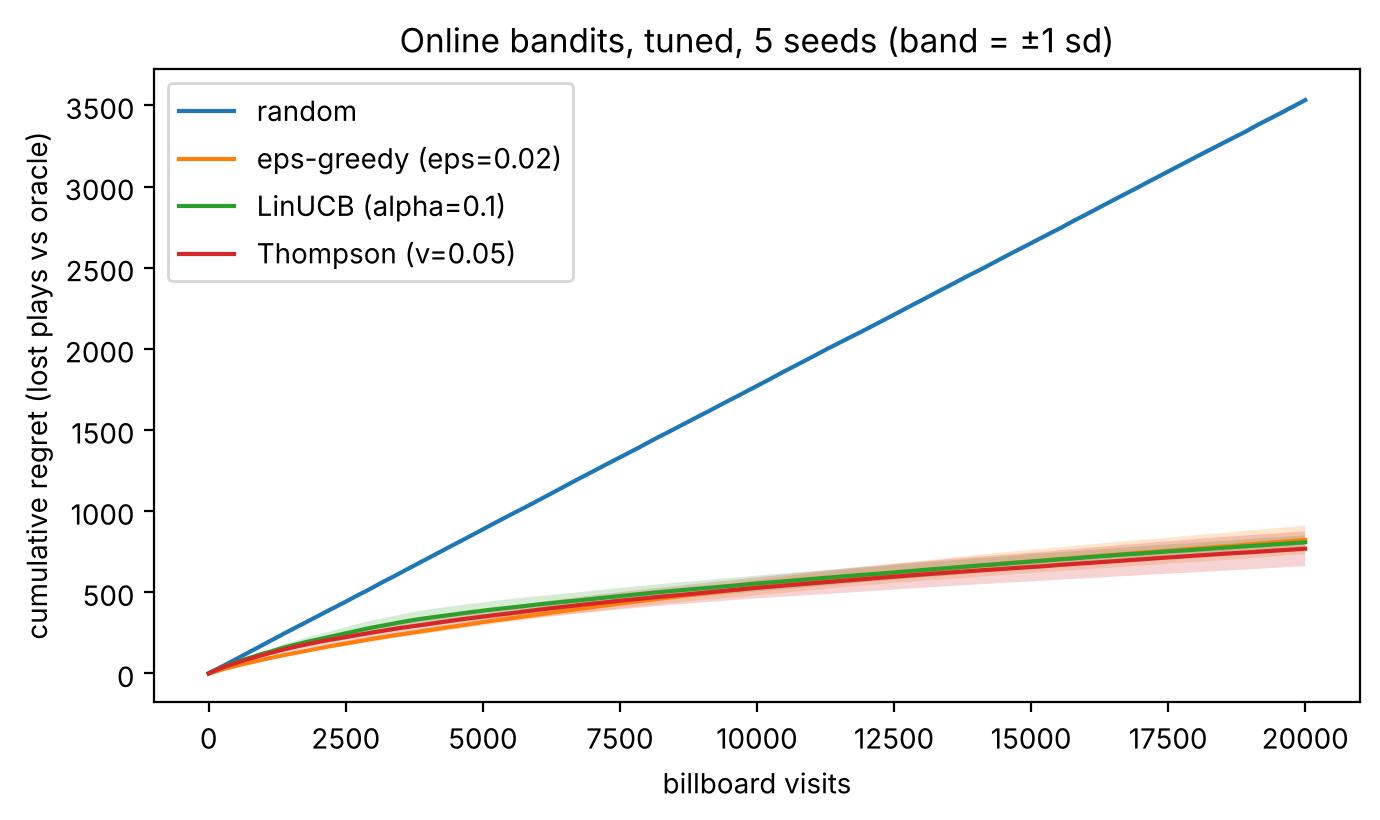

In [9]:
plt.figure(figsize=(7, 4.2))
x = np.arange(1, T + 1)
for algo, c in curves.items():
    m, sd = c.mean(0), c.std(0)
    plt.plot(x, m, label=algo); plt.fill_between(x, m - sd, m + sd, alpha=0.2)
plt.xlabel("billboard visits"); plt.ylabel("cumulative regret (lost plays vs oracle)")
plt.title("Online bandits, tuned, 5 seeds (band = ±1 sd)")
plt.legend(); plt.tight_layout(); plt.savefig("figures/fig3_online_regret.png", dpi=130); plt.show()

**How to read it (verified numbers).** Untuned, with textbook defaults (ε = 0.1, α = 0.5, v = 0.3), Thompson sampling was the *worst* learner (~1,200 regret vs ~990 for ε-greedy). After tuning each knob on separate seeds, all three land within one standard deviation of each other (~770–820), and all cut regret by more than 4× vs random. The lesson for this setup: **tuning the exploration knob mattered more than the choice of algorithm.** Don't trust a bandit comparison that doesn't say how each method was tuned.

## 5. Beyond the talk: evaluating a new policy on non-uniform logs

Replay works because Netflix's exploration slice is **uniform**: every title has the same chance of being logged, so matched rows are a fair sample. But most production logs come from an ε-greedy system, where the greedy title shows up far more often. Replay then over-represents members whose new-policy pick happens to agree with the old greedy pick.

Setup (plain): the **logging** system is ε-greedy around the greedy model (ε = 0.2), propensities logged. We want the take rate of the **incrementality** policy. Because we built the simulator, we know its true value. We draw 200 logs of 5,000 visits each and compare five estimators:

| estimator | plain operation |
|---|---|
| **Replay** (Netflix) | average reward over rows where pick == logged title |
| **IPS** | sum of `match · reward / propensity`, divided by n |
| **SNIPS** | same, divided by the sum of `match / propensity` instead of n |
| **DM** (direct method) | average of the model's predicted p̂1 for the new policy's pick |
| **DR** (doubly robust) | DM + IPS-weighted correction of the model's error on matched rows |

DM and DR need a reward model. We run each with two: the **good** logistic model from section 3, and a **crude** one (each title's average take rate, ignoring who the member is). In real life your reward model is somewhere in between, and you don't know where.

We also rerun with uniform logging, where replay should be fine.

In [10]:
rng = np.random.default_rng(SEED)
train = log_visits(rng, 40_000, uniform)            # separate slice to fit the models
m1, m0 = fit_models(train, rng)

def greedy_eps_probs(users, eps=0.2):
    g = score_all(m1, users).argmax(1)
    probs = np.full((len(users), K), eps / K)
    probs[np.arange(len(users)), g] += 1 - eps
    return probs

def target_pick(users):
    return (score_all(m1, users) - score_all(m0, users)).argmax(1)   # incrementality policy

# true value of the target policy (large sample, true p1)
big = rng.integers(0, N_USERS, 50_000)
TRUE_V = P1[big, target_pick(big)].mean()

# a deliberately CRUDE reward model: each title's average take rate, ignoring the member.
# Real reward models are never exactly right; this shows what happens when the model is wrong.
title_avg = pd.Series(train["play"]).groupby(train["arms"]).mean().reindex(range(K)).values

def estimators(log):
    users, arms, r, p = log["users"], log["arms"], log["play"], log["prop"]
    n = len(users); idx = np.arange(n)
    pick = target_pick(users)
    match = (pick == arms).astype(float)
    w = match / p                                     # inverse-propensity weight (0 if no match)
    out = {"Replay": r[match == 1].mean(),
           "IPS": (w * r).mean(),
           "SNIPS": (w * r).sum() / w.sum()}
    for tag, rhat_all in [("good model", score_all(m1, users)),
                          ("crude model", np.tile(title_avg, (n, 1)))]:
        rhat_pick, rhat_logged = rhat_all[idx, pick], rhat_all[idx, arms]
        out[f"DM ({tag})"] = rhat_pick.mean()
        out[f"DR ({tag})"] = (rhat_pick + w * (r - rhat_logged)).mean()
    return out

out = []
for logging_name, probs_fn in [("eps-greedy logs", greedy_eps_probs), ("uniform logs", uniform)]:
    for rep in range(200):
        est = estimators(log_visits(np.random.default_rng(1000 + rep), 5_000, probs_fn))
        for k_, v_ in est.items():
            out.append(dict(logging=logging_name, estimator=k_, value=v_))
ope = pd.DataFrame(out)
ope["error"] = ope.value - TRUE_V
tab = ope.groupby(["logging", "estimator"]).error.agg(
    bias="mean", sd="std", rmse=lambda e: np.sqrt((e ** 2).mean())).round(4)
print(f"true take rate of the incrementality policy: {TRUE_V:.4f}")
tab

true take rate of the incrementality policy: 0.2317


bias      sd    rmse
logging         estimator                               
eps-greedy logs DM (crude model) -0.1201  0.0003  0.1201
                DM (good model)  -0.0020  0.0011  0.0023
                DR (crude model) -0.0009  0.0452  0.0451
                DR (good model)  -0.0007  0.0458  0.0457
                IPS              -0.0013  0.0467  0.0466
                Replay            0.0330  0.0097  0.0344
                SNIPS             0.0008  0.0464  0.0463
uniform logs    DM (crude model) -0.1201  0.0003  0.1201
                DM (good model)  -0.0020  0.0011  0.0023
                DR (crude model) -0.0006  0.0268  0.0267
                DR (good model)  -0.0011  0.0254  0.0254
                IPS              -0.0004  0.0291  0.0291
                Replay           -0.0008  0.0261  0.0260
                SNIPS            -0.0008  0.0261  0.0260

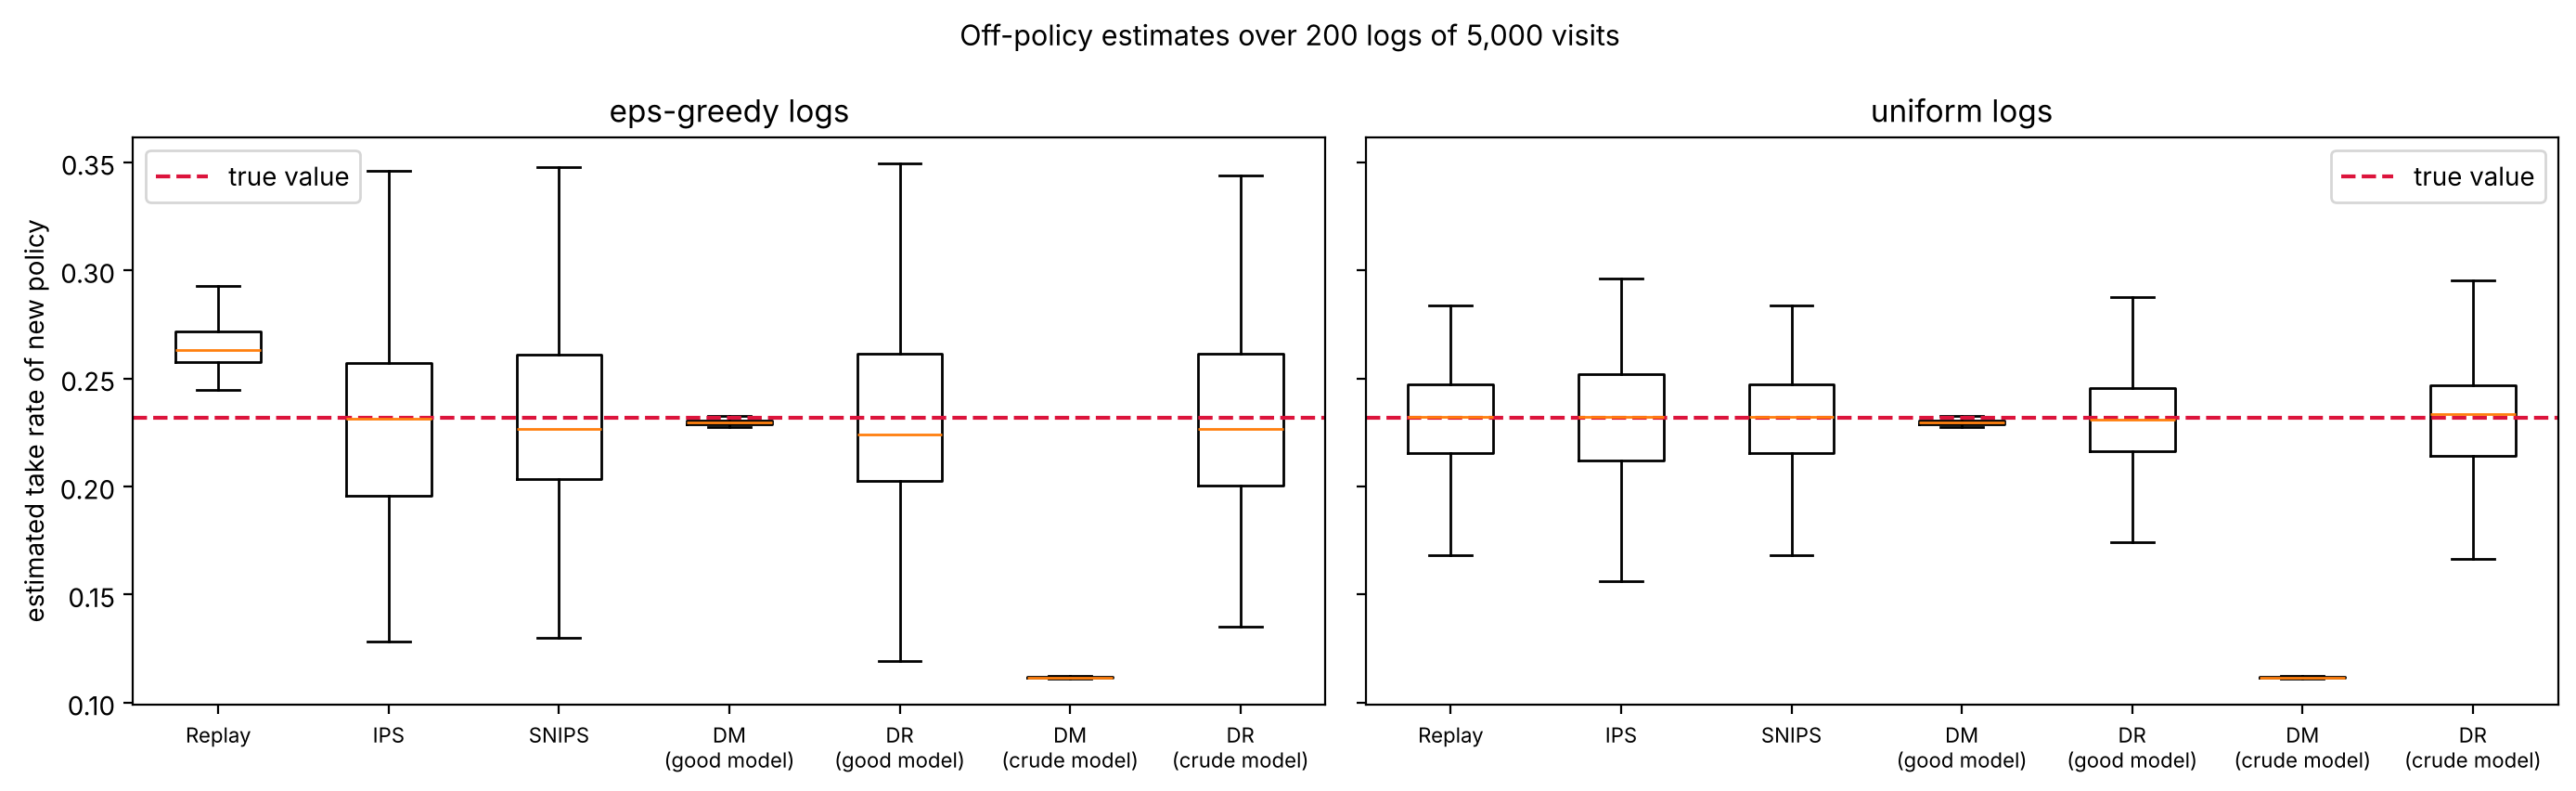

In [11]:
ests = ["Replay", "IPS", "SNIPS", "DM (good model)", "DR (good model)", "DM (crude model)", "DR (crude model)"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3), sharey=True)
for ax, lg in zip(axes, ["eps-greedy logs", "uniform logs"]):
    data = [ope[(ope.logging == lg) & (ope.estimator == e)].value for e in ests]
    ax.boxplot(data, showfliers=False)
    ax.set_xticks(range(1, len(ests) + 1))
    ax.set_xticklabels([e.replace(" (", "\n(") for e in ests], fontsize=8)
    ax.axhline(TRUE_V, color="crimson", ls="--", label="true value")
    ax.set_title(lg); ax.legend()
axes[0].set_ylabel("estimated take rate of new policy")
plt.suptitle("Off-policy estimates over 200 logs of 5,000 visits", fontsize=11)
plt.tight_layout(); plt.savefig("figures/fig4_ope.png", dpi=130); plt.show()

**How to read it (verified numbers, true value = 0.232):**
- **Replay on ε-greedy logs overstates by +0.033 (+14%)**, with a small spread — so it looks precise *and* wrong. On uniform logs the bias disappears. Replay is only safe on uniform logs.
- **IPS and SNIPS** are unbiased on both, but noisy: ±0.046 (±20%) at 5,000 visits, because the new policy rarely agrees with the logged pick.
- **DM** is near-perfect with the good model (our simulator is easy to model) and **off by −0.12 (−52%)** with the crude one. Same estimator, the model decides.
- **DR** stays unbiased with *either* model. That's the "doubly robust" promise, shown. It does not shrink the variance much here: billboard plays are 0/1 coin flips, and no reward model removes that noise.

## 6. What this rebuild shows, and what it can't

**Shows (verified end to end, numbers above):**
1. The metric picks the winner. Greedy wins take rate (0.281 vs 0.229); incrementality wins incremental plays (+28%: 0.158 vs 0.123) and sends 26% of billboards to the 5 most popular titles instead of 65%. Replay on take rate alone picks greedy — the same offline result Netflix reported.
2. The baseline-vs-lift pattern can be recovered from uniform logs with two plain logistic regressions (estimated vs true lift: correlation 0.87).
3. Online, once each algorithm's knob is tuned, ε-greedy, LinUCB and Thompson sampling are statistically tied here. Tuning mattered more than the algorithm.
4. Replay needs uniform logs (+14% bias otherwise). DR is the safe default when logs aren't uniform: unbiased whether or not the reward model is good. DM is only as good as its model.

**Can't show:** real effect sizes. Plays are simulated (Assumptions 1–4), and Assumption 2 *builds in* the "low baseline → big lift" pattern. The online bandit section optimizes take rate, not incremental plays (incremental reward isn't observed per visit — that needs a model, exactly as the incrementality policy does).

Source: [A Multi-Armed Bandit Framework for Recommendations at Netflix](https://aicouncil.com/talks/a-multi-armed-bandit-framework-for-recommendations-at-netflix). Code: [github.com/ZFayFay/netflix-bandits-replication](https://github.com/ZFayFay/netflix-bandits-replication)